# 二値化手法の比較

フォント画像（アンチエイリアス付きグレースケール）を二値化する手法を比較し、
細字・薄字フォントのストローク消失リスクを定量化する。

**規約**: stroke=0（暗い）、background=1（明るい）

## 比較する手法

| 手法 | 説明 |
|---|---|
| Fixed (0.5) | グローバル固定閾値 |
| Otsu | ヒストグラムのクラス間分散を最大化する自動閾値 |
| Adaptive mean | 局所平均を閾値に使う適応二値化（細線に有利） |

Sauvola / Niblack（局所分散ベース）は文書スキャン向きで skimage が必要なため除外。  
フォント画像は均一照明・高コントラストであり、適応手法の恩恵は限定的。

In [2]:
import sys
# sys.path.insert(0, "../src")

from pathlib import Path
import numpy as np
from scipy.ndimage import gaussian_filter, uniform_filter
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

IMAGE_DIR = Path("data/datasets/font2dataset_ascii_google/images")
IMAGE_SIZE = 64

# Thin/Light フォントが ascii_google になければ uppercase_google_64 にフォールバック
FALLBACK_DIR = Path("data/datasets/font2dataset_upper_google_64/images")

print(f"IMAGE_DIR exists: {IMAGE_DIR.exists()}")
print(f"FALLBACK_DIR exists: {FALLBACK_DIR.exists()}")

IMAGE_DIR exists: True
FALLBACK_DIR exists: True


In [3]:
def load_gray(path: Path) -> np.ndarray:
    """グレースケール float32 [0,1] でロード (stroke=0, background=1)"""
    return np.array(
        Image.open(path).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE)),
        dtype=np.float32,
    ) / 255.0


def binarize_global(img: np.ndarray, threshold: float = 0.5) -> np.ndarray:
    """固定閾値二値化。threshold 以上 → background(1), 未満 → stroke(0)"""
    return (img >= threshold).astype(np.float32)


def otsu_threshold(img: np.ndarray) -> float:
    """Otsu 法で最適閾値を計算する（numpy 実装）。

    ヒストグラムの二峰性を前提にクラス間分散を最大化する。
    フォント画像の場合: peak near 0 (stroke) + peak near 1 (background)。
    """
    hist, bins = np.histogram(img.ravel(), bins=256, range=(0.0, 1.0))
    bin_centers = (bins[:-1] + bins[1:]) / 2
    total = hist.sum()
    w0 = np.cumsum(hist) / total
    w1 = 1.0 - w0
    mu0 = np.cumsum(hist * bin_centers) / (np.cumsum(hist) + 1e-10)
    mu1 = (
        (np.sum(hist * bin_centers) - np.cumsum(hist * bin_centers))
        / (total * w1 + 1e-10)
    )
    sigma_b = w0 * w1 * (mu0 - mu1) ** 2
    return float(bin_centers[np.argmax(sigma_b)])


def binarize_otsu(img: np.ndarray) -> tuple[np.ndarray, float]:
    thr = otsu_threshold(img)
    return (img >= thr).astype(np.float32), thr


def binarize_adaptive(img: np.ndarray, block_size: int = 15, C: float = 0.05) -> np.ndarray:
    """局所平均適応二値化（Bradley フィルタ相当）。

    局所平均 - C を閾値とする。C > 0 にすることで stroke 側への判定が緩くなり
    細線が生き残りやすくなる（C=0 だと全白画像が全て stroke 判定される副作用がある）。
    """
    local_mean = uniform_filter(img, size=block_size)
    return (img >= local_mean - C).astype(np.float32)


def blur_binary(binary: np.ndarray, sigma: float) -> np.ndarray:
    """二値画像にガウシアンブラーを適用してグレースケール化する"""
    return gaussian_filter(binary.astype(np.float64), sigma=sigma).astype(np.float32)


print("Helper functions defined.")

Helper functions defined.


## 1. グレースケール → 二値化 → ローパスフィルタ → グレースケール

二値化後にガウシアンブラーをかけると、アンチエイリアシングに相当するグレースケールが得られる。  
σ が大きいほど境界がぼけるが、細線がつぶれるリスクも増える。

Target: data/datasets/font2dataset_ascii_google/images/0065_ABeeZee-Regular_000.png


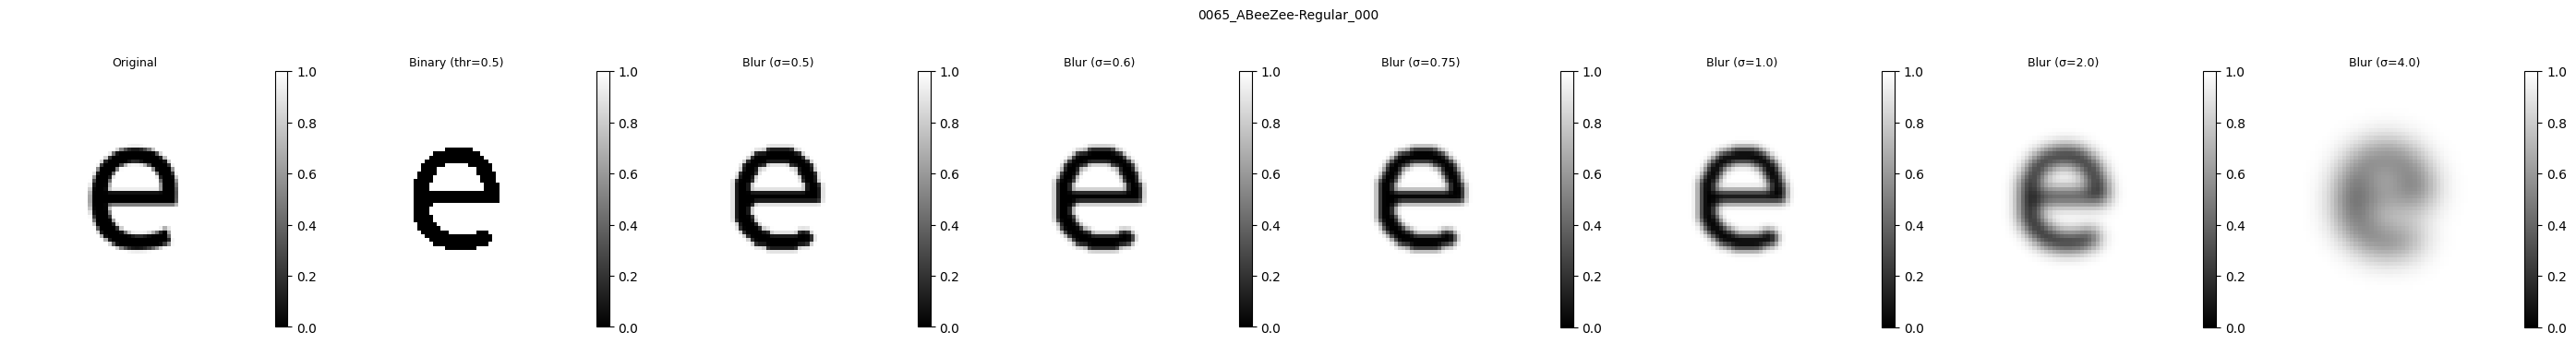

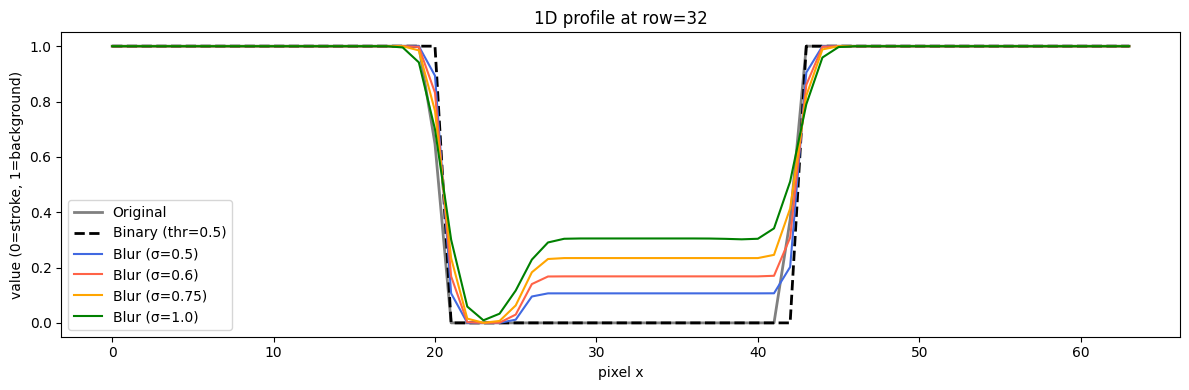

In [4]:
target_path = next(IMAGE_DIR.glob("0065_ABeeZee-Regular_000.png"), None)
if target_path is None:
    target_path = next(IMAGE_DIR.glob("0065_*Regular*_000.png"), None)
if target_path is None:
    target_path = next(IMAGE_DIR.glob("0065_*.png"), None)

print(f"Target: {target_path}")

img = load_gray(target_path)
binary = binarize_global(img)

sigmas = [0.5, 0.6, 0.75, 1.0, 2.0, 4.0]
blurred = [blur_binary(binary, s) for s in sigmas]

# --- 画像グリッド ---
all_imgs = [img, binary] + blurred
all_titles = ["Original", "Binary (thr=0.5)"] + [f"Blur (σ={s})" for s in sigmas]

fig, axes = plt.subplots(1, len(all_imgs), figsize=(3.5 * len(all_imgs), 4))
for ax, im, title in zip(axes, all_imgs, all_titles):
    obj = ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
    plt.colorbar(obj, ax=ax, fraction=0.046)

plt.suptitle(target_path.stem, fontsize=10)
plt.tight_layout()
plt.show()

# --- 中央行の 1D プロファイル ---
row = IMAGE_SIZE // 2
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(IMAGE_SIZE)
ax.plot(x, img[row], color="gray", linewidth=2, label="Original")
ax.plot(x, binary[row], color="black", linewidth=2, linestyle="--", label="Binary (thr=0.5)")
colors = ["royalblue", "tomato", "orange", "green"]
for b, s, c in zip(blurred, sigmas, colors):
    ax.plot(x, b[row], color=c, linewidth=1.5, label=f"Blur (σ={s})")
ax.set_xlabel("pixel x")
ax.set_ylabel("value (0=stroke, 1=background)")
ax.set_title(f"1D profile at row={row}")
ax.legend()
ax.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

## 2. 二値化手法の比較

Regular / Bold / Thin フォントに対して 3 手法を適用して画像を比較する。  
Otsu 法の閾値は自動推定されるため、ヘッドライン（Thin）では Background ピークに引っ張られて
閾値が 0.5 より高くなる（= ストローク側に寛大になる）可能性がある。

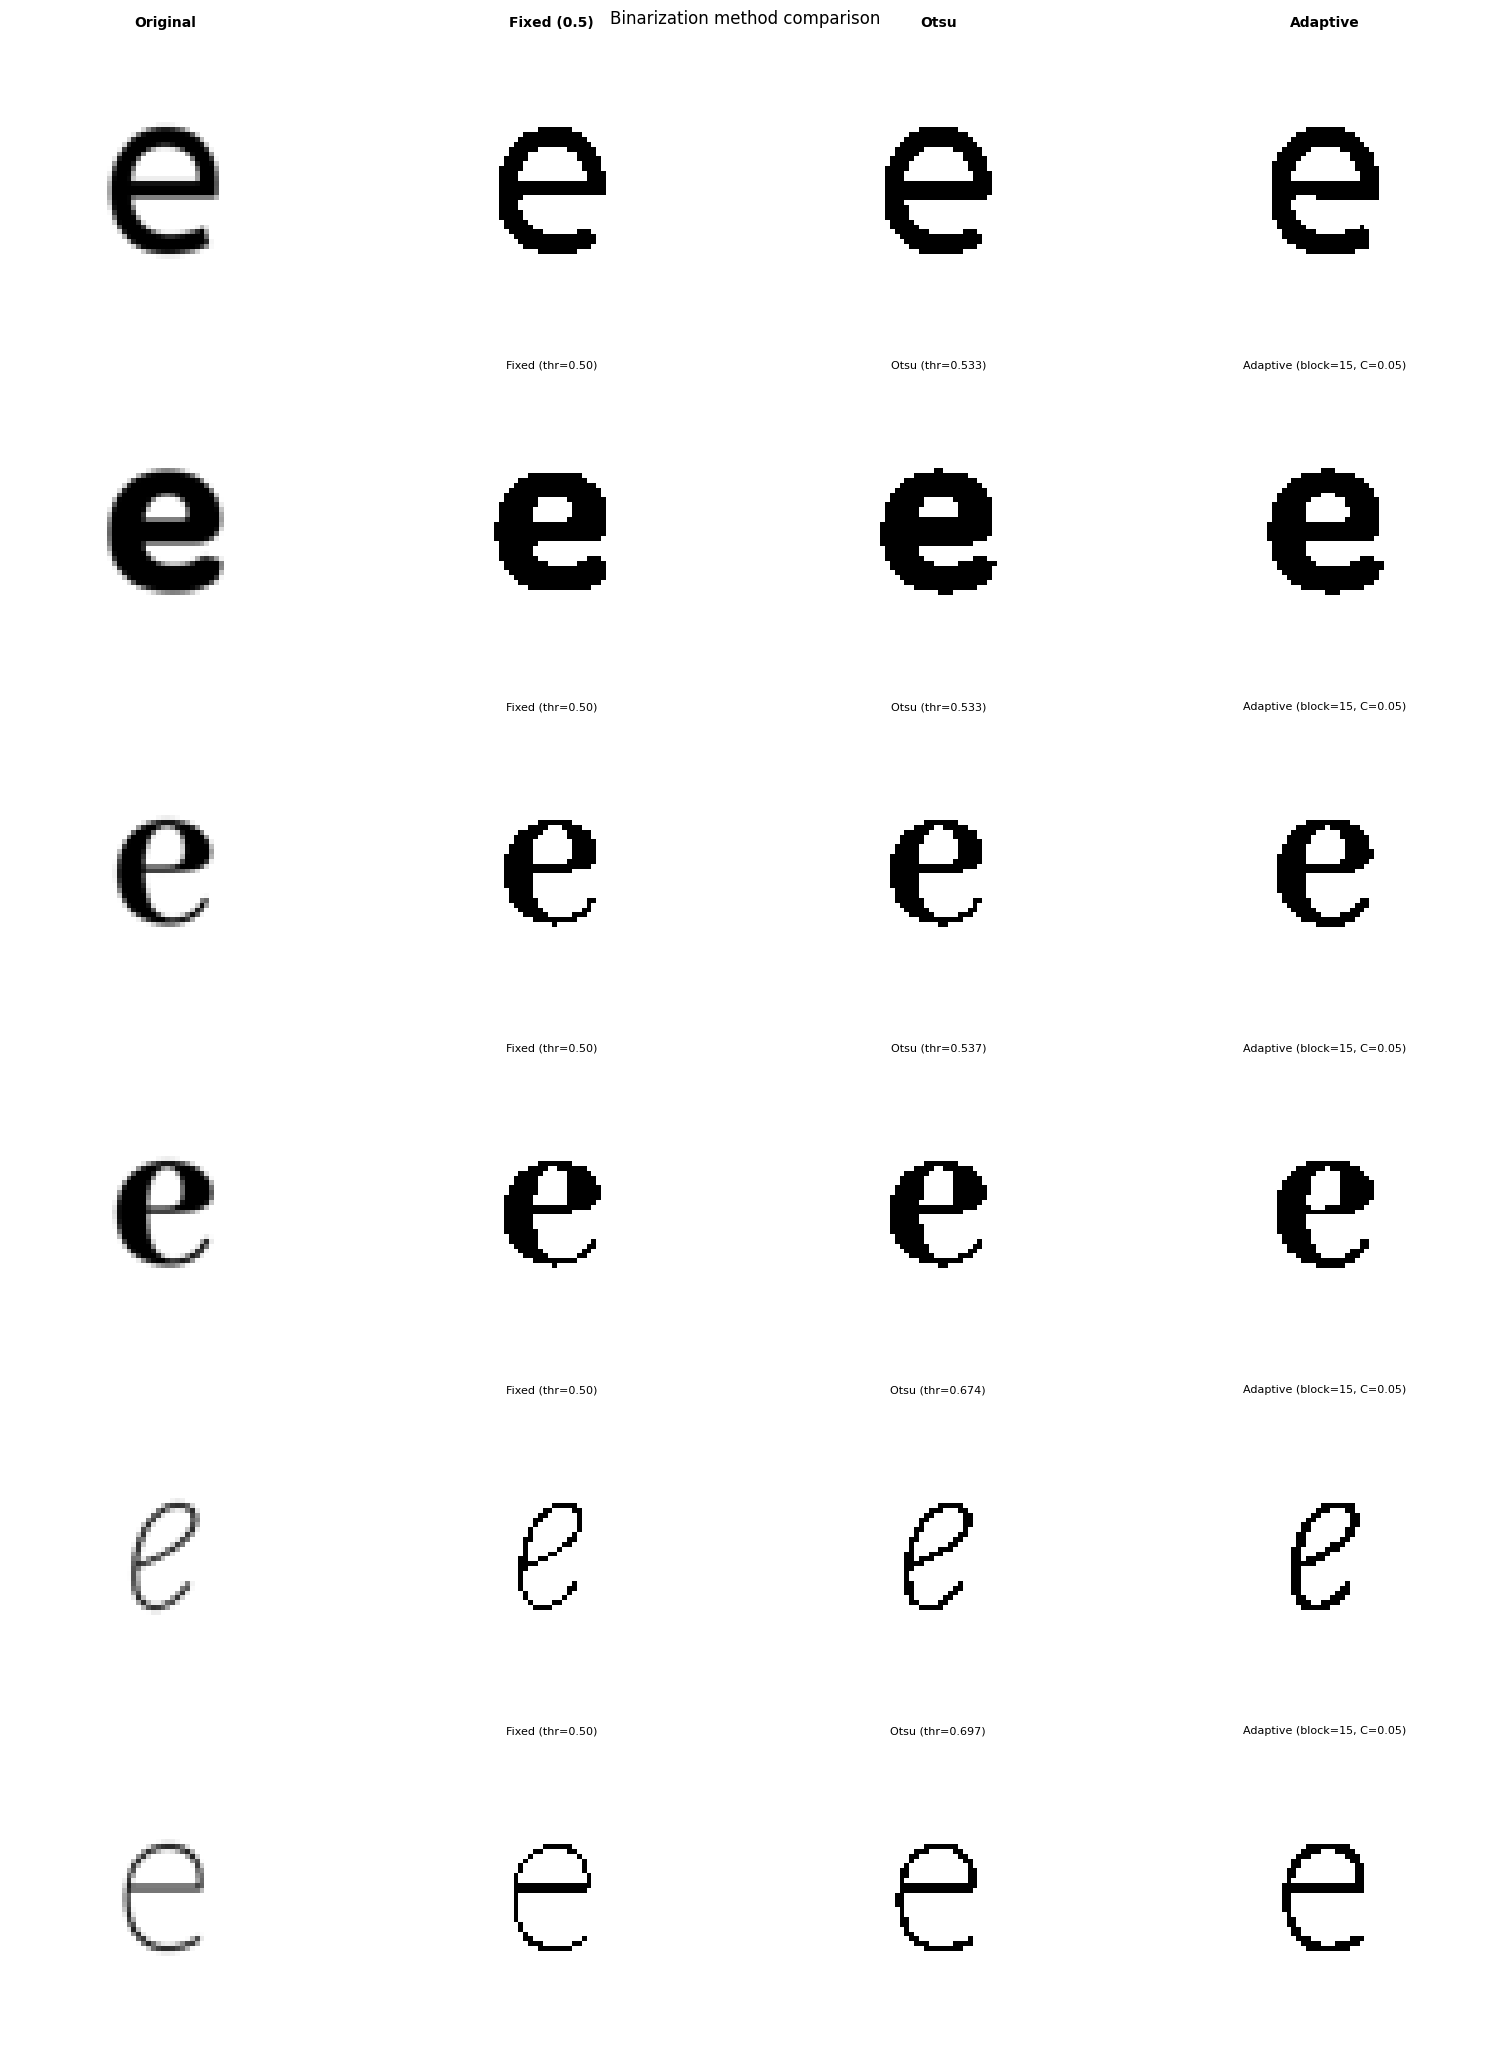

In [5]:
# Regular / Bold / Thin の代表フォントをピックアップ
def find_fonts(pattern: str, n: int = 2) -> list[Path]:
    return sorted(IMAGE_DIR.glob(pattern))[:n]

sample_groups = [
    ("Regular", find_fonts("0065_*Regular*_000.png") + find_fonts("0066_*Regular*_000.png")),
    ("Bold",    find_fonts("0065_*Bold*_000.png")    + find_fonts("0066_*Bold*_000.png")),
    ("Thin",    find_fonts("0065_*Thin*_000.png")    + find_fonts("0066_*Thin*_000.png")),
]
# 各グループから最大 2 枚
sample_groups = [(label, paths[:2]) for label, paths in sample_groups if paths]

methods = [
    ("Original", None),
    ("Fixed (0.5)", lambda img: (binarize_global(img), 0.5)),
    ("Otsu", lambda img: binarize_otsu(img)),
    ("Adaptive\n(block=15, C=0.05)", lambda img: (binarize_adaptive(img), None)),
]

rows = sum(len(paths) for _, paths in sample_groups)
fig, axes = plt.subplots(rows, len(methods), figsize=(4 * len(methods), 3.5 * rows))
if rows == 1:
    axes = axes[np.newaxis, :]

row_idx = 0
for group_label, paths in sample_groups:
    for path in paths:
        img = load_gray(path)
        ax_row = axes[row_idx]

        # Original
        ax_row[0].imshow(img, cmap="gray", vmin=0, vmax=1)
        ax_row[0].set_ylabel(f"{group_label}\n{path.stem[:20]}", fontsize=7)
        ax_row[0].axis("off")

        # Fixed
        bw, thr = binarize_global(img), 0.5
        ax_row[1].imshow(bw, cmap="gray", vmin=0, vmax=1)
        ax_row[1].set_title(f"Fixed (thr=0.50)", fontsize=8)
        ax_row[1].axis("off")

        # Otsu
        bw_o, thr_o = binarize_otsu(img)
        ax_row[2].imshow(bw_o, cmap="gray", vmin=0, vmax=1)
        ax_row[2].set_title(f"Otsu (thr={thr_o:.3f})", fontsize=8)
        ax_row[2].axis("off")

        # Adaptive
        bw_a = binarize_adaptive(img)
        ax_row[3].imshow(bw_a, cmap="gray", vmin=0, vmax=1)
        ax_row[3].set_title("Adaptive (block=15, C=0.05)", fontsize=8)
        ax_row[3].axis("off")

        row_idx += 1

# 列ヘッダー
for ax, label in zip(axes[0], ["Original", "Fixed (0.5)", "Otsu", "Adaptive"]):
    ax.set_title(label, fontsize=10, fontweight="bold")

plt.suptitle("Binarization method comparison", fontsize=12)
plt.tight_layout()
plt.show()

## 3. 細字フォントのストローク消失確認

**定量化の方法**:
- `reference`: 寛大な閾値 0.85 で二値化 → 「確実にストローク」の参照マスク
- `method_out`: 各手法の出力
- `loss_ratio = 1 - stroke_method / stroke_ref` … 0 = 消失なし、1 = 全消失
- `difference image`: reference にあって method_out にない画素を赤でハイライト

Thin / Light / ExtraLight フォントを対象とし、複数文字にわたって統計を集計する。

In [6]:
# Thin/Light フォントを収集（枚数が多いため上限を設ける）
MAX_THIN_IMAGES = 500
thin_patterns = ["*Thin*", "*ExtraLight*", "*Light*"]

thin_paths: list[Path] = []
for pat in thin_patterns:
    thin_paths.extend(sorted(IMAGE_DIR.glob(f"*_{pat}_*.png")))
    if len(thin_paths) >= MAX_THIN_IMAGES:
        break

thin_paths = thin_paths[:MAX_THIN_IMAGES]

# フォールバック
if not thin_paths:
    print(f"ascii_google に Thin/Light フォントなし → {FALLBACK_DIR} を使用")
    for pat in thin_patterns:
        thin_paths.extend(sorted(FALLBACK_DIR.glob(f"*_{pat}_*.png")))
        if len(thin_paths) >= MAX_THIN_IMAGES:
            break
    thin_paths = thin_paths[:MAX_THIN_IMAGES]

print(f"Found {len(thin_paths)} thin/light font images (cap={MAX_THIN_IMAGES})")
if thin_paths:
    print("Examples:", [p.name for p in thin_paths[:5]])

Found 500 thin/light font images (cap=500)
Examples: ['0020_AlegreyaSans-ThinItalic_000.png', '0020_AlegreyaSans-Thin_000.png', '0020_AlegreyaSansSC-ThinItalic_000.png', '0020_AlegreyaSansSC-Thin_000.png', '0020_Barlow-ThinItalic_000.png']


In [7]:
REF_THRESHOLD = 0.85  # 寛大な閾値（確実にストロークと見なすピクセルのみ抽出）

method_names = ["Fixed (0.5)", "Otsu", "Adaptive"]
loss_records: list[dict] = []

for path in thin_paths:
    img = load_gray(path)
    ref = binarize_global(img, threshold=REF_THRESHOLD)
    stroke_ref = (ref < 0.5).sum()
    if stroke_ref == 0:
        continue  # 空白画像はスキップ

    bw_fixed = binarize_global(img, 0.5)
    bw_otsu, _ = binarize_otsu(img)
    bw_adapt = binarize_adaptive(img)

    for name, bw in zip(method_names, [bw_fixed, bw_otsu, bw_adapt]):
        stroke_out = (bw < 0.5).sum()
        loss_ratio = 1.0 - stroke_out / (stroke_ref + 1e-6)
        loss_records.append({
            "path": path,
            "method": name,
            "loss_ratio": float(loss_ratio),
            "stroke_ref": int(stroke_ref),
            "stroke_out": int(stroke_out),
        })

print(f"Evaluated {len(loss_records) // len(method_names)} images × {len(method_names)} methods")

Evaluated 420 images × 3 methods


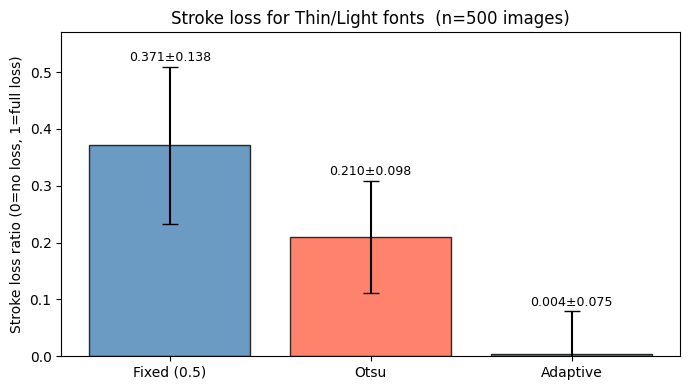

  Fixed (0.5)              : mean loss=0.3715  std=0.1382
  Otsu                     : mean loss=0.2100  std=0.0984
  Adaptive                 : mean loss=0.0045  std=0.0746


In [8]:
import collections

if not loss_records:
    print("No data — Thin/Light フォントが見つかりませんでした")
else:
    # 手法別に loss_ratio を集計
    by_method: dict[str, list[float]] = collections.defaultdict(list)
    for r in loss_records:
        by_method[r["method"]].append(r["loss_ratio"])

    means = [np.mean(by_method[m]) for m in method_names]
    stds  = [np.std(by_method[m])  for m in method_names]

    fig, ax = plt.subplots(figsize=(7, 4))
    colors = ["steelblue", "tomato", "seagreen"]
    bars = ax.bar(method_names, means, yerr=stds, capsize=6,
                  color=colors, alpha=0.8, edgecolor="black")
    ax.set_ylabel("Stroke loss ratio (0=no loss, 1=full loss)")
    ax.set_title(f"Stroke loss for Thin/Light fonts  (n={len(thin_paths)} images)")
    ax.set_ylim(0, max(means) * 1.4 + 0.05)

    for bar, mean, std in zip(bars, means, stds):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + std + 0.005,
            f"{mean:.3f}±{std:.3f}",
            ha="center", va="bottom", fontsize=9,
        )

    plt.tight_layout()
    plt.show()

    for name, mean, std in zip(method_names, means, stds):
        print(f"  {name:25s}: mean loss={mean:.4f}  std={std:.4f}")

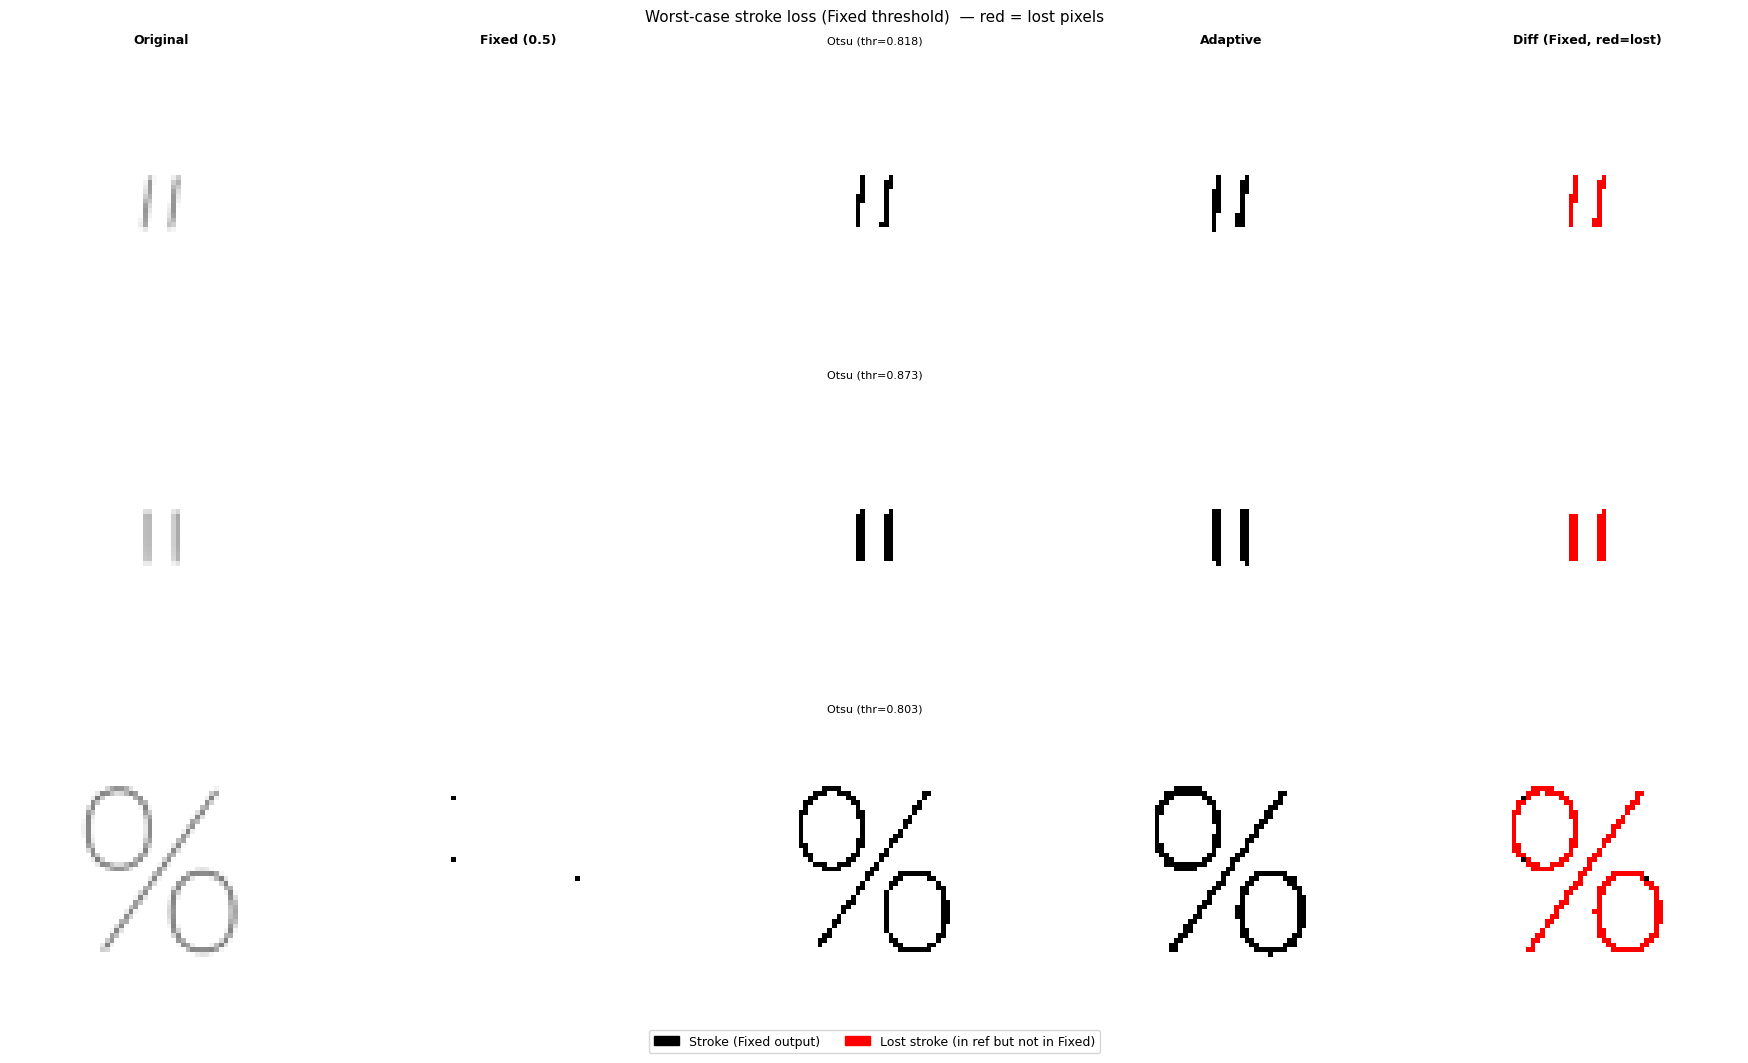

In [9]:
if loss_records:
    # Fixed(0.5) で loss_ratio が最大のフォント Top-3 を表示
    fixed_records = [r for r in loss_records if r["method"] == "Fixed (0.5)"]
    fixed_records.sort(key=lambda r: r["loss_ratio"], reverse=True)
    top_k = fixed_records[:3]

    if not top_k:
        print("No records for Fixed method")
    else:
        n = len(top_k)
        fig, axes = plt.subplots(n, 5, figsize=(18, 3.5 * n))
        if n == 1:
            axes = axes[np.newaxis, :]

        col_titles = ["Original", "Fixed (0.5)", "Otsu", "Adaptive", "Diff (Fixed, red=lost)"]
        for ax, title in zip(axes[0], col_titles):
            ax.set_title(title, fontsize=9, fontweight="bold")

        for ax_row, rec in zip(axes, top_k):
            path = rec["path"]
            img = load_gray(path)
            ref = binarize_global(img, threshold=REF_THRESHOLD)
            bw_fixed = binarize_global(img, 0.5)
            bw_otsu, thr_o = binarize_otsu(img)
            bw_adapt = binarize_adaptive(img)

            # 差分画像: reference にあって fixed にない画素を赤でハイライト
            lost_mask = (ref < 0.5) & (bw_fixed >= 0.5)  # 消失ピクセル
            diff_rgb = np.stack([np.ones_like(img)] * 3, axis=-1)  # 白背景
            diff_rgb[bw_fixed < 0.5] = [0, 0, 0]    # fixed output のストローク = 黒
            diff_rgb[lost_mask] = [1, 0, 0]          # 消失ピクセル = 赤

            for ax, im, cmap in zip(
                ax_row,
                [img, bw_fixed, bw_otsu, bw_adapt],
                ["gray"] * 4,
            ):
                ax.imshow(im, cmap=cmap, vmin=0, vmax=1)
                ax.axis("off")

            ax_row[2].set_title(f"Otsu (thr={thr_o:.3f})", fontsize=8)
            ax_row[4].imshow(diff_rgb)
            ax_row[4].axis("off")

            ax_row[0].set_ylabel(
                f"{path.stem[:22]}\nloss={rec['loss_ratio']:.3f}",
                fontsize=7,
            )

        # 凡例
        legend_patches = [
            mpatches.Patch(color="black", label="Stroke (Fixed output)"),
            mpatches.Patch(color="red",   label="Lost stroke (in ref but not in Fixed)"),
        ]
        fig.legend(handles=legend_patches, loc="lower center", ncol=2, fontsize=9,
                   bbox_to_anchor=(0.5, -0.02))

        plt.suptitle("Worst-case stroke loss (Fixed threshold)  — red = lost pixels", fontsize=11)
        plt.tight_layout()
        plt.show()

## 4. 二値化の実行時間比較

各手法を同一画像群に適用して 1 枚あたりの平均実行時間を計測する。
Fixed は単純な閾値比較、Otsu はヒストグラム計算、Adaptive は局所平均
(`uniform_filter`) のコストが乗る。`load_gray` の I/O は除外し、
二値化処理のみを `time.perf_counter` で計測する。

Benchmarking on 200 images (64x64)


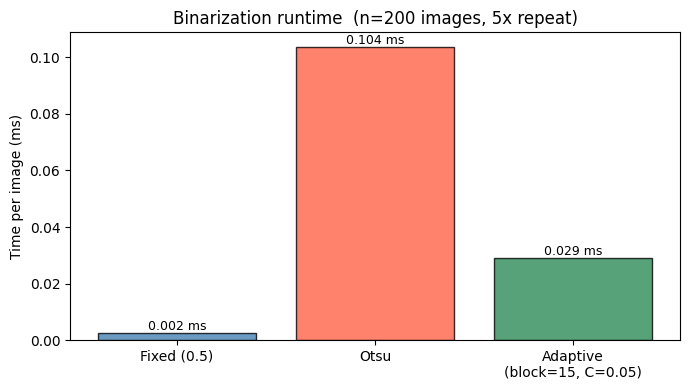

  Fixed (0.5)                 : 0.0023 ms/image
  Otsu                        : 0.1037 ms/image
  Adaptive (block=15, C=0.05) : 0.0291 ms/image


In [10]:
import time

# 計測対象の画像を事前ロード（I/O を計測から除外）
BENCH_N = 200
bench_paths = sorted(IMAGE_DIR.glob("*.png"))[:BENCH_N]
bench_imgs = [load_gray(p) for p in bench_paths]
print(f"Benchmarking on {len(bench_imgs)} images ({IMAGE_SIZE}x{IMAGE_SIZE})")

bench_methods = [
    ("Fixed (0.5)", lambda img: binarize_global(img, 0.5)),
    ("Otsu", lambda img: binarize_otsu(img)),
    ("Adaptive\n(block=15, C=0.05)", lambda img: binarize_adaptive(img)),
]

N_REPEAT = 5  # 各画像を複数回処理して平均を安定させる
timing: dict[str, float] = {}
for name, fn in bench_methods:
    # ウォームアップ（初回 JIT/キャッシュの影響を除外）
    fn(bench_imgs[0])
    start = time.perf_counter()
    for _ in range(N_REPEAT):
        for img in bench_imgs:
            fn(img)
    elapsed = time.perf_counter() - start
    per_image_ms = elapsed / (N_REPEAT * len(bench_imgs)) * 1e3
    timing[name] = per_image_ms

# --- バープロット ---
labels = [name for name, _ in bench_methods]
values = [timing[name] for name in labels]
colors = ["steelblue", "tomato", "seagreen"]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, values, color=colors, alpha=0.8, edgecolor="black")
ax.set_ylabel("Time per image (ms)")
ax.set_title(f"Binarization runtime  (n={len(bench_imgs)} images, {N_REPEAT}x repeat)")
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{v:.3f} ms", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

for name in labels:
    print(f"  {name.replace(chr(10), ' '):28s}: {timing[name]:.4f} ms/image")